## Setup

In [1]:
import tensorflow
import keras
import matplotlib
import numpy as np

In [2]:
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import InputLayer, Dense, Flatten, Dropout, Conv2D, MaxPooling2D, BatchNormalization
from tensorflow.keras import utils as np_utils
import matplotlib.pyplot as plt

## Load Data

In [3]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

In [4]:
X_train.shape, X_test.shape

((60000, 28, 28), (10000, 28, 28))

Cada imagem possui $28\cdot28 = 784$ pixels

In [5]:
X_train, X_train.max()

(array([[[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],
 
        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],
 
        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],
 
        ...,
 
        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],
 
        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],

In [6]:
y_train, y_train.max()

(array([5, 0, 4, ..., 5, 6, 8], shape=(60000,), dtype=uint8), np.uint8(9))

Text(0.5, 1.0, 'Number 5')

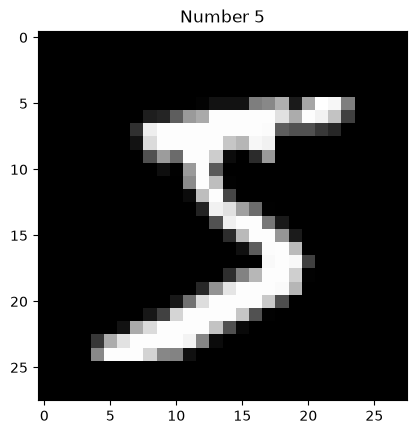

In [7]:
plt.imshow(X_train[0], cmap='gray')
plt.title('Number ' + str(y_train[0]))

Text(0.5, 1.0, 'Number 0')

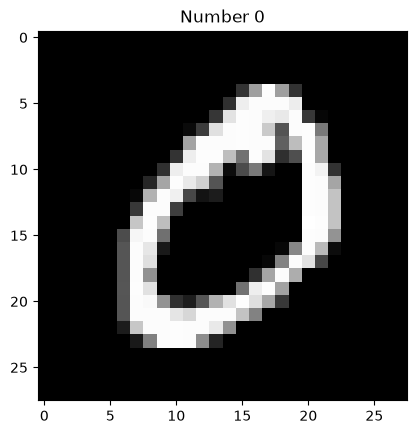

In [8]:
plt.imshow(X_train[1], cmap='gray')
plt.title('Number ' + str(y_train[1]))

Text(0.5, 1.0, 'Number 4')

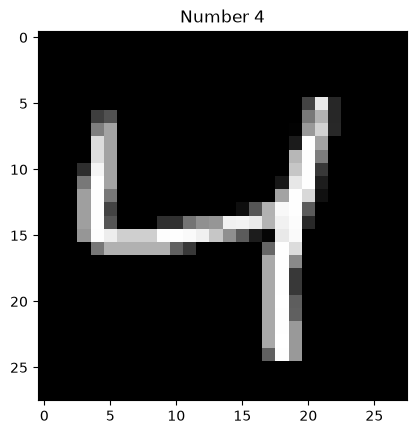

In [9]:
plt.imshow(X_train[2], cmap='gray')
plt.title('Number ' + str(y_train[2]))

## Preprocesssing
Uma imagem colorida possui três canais $(R, G, B)$ mas vamos nos restringir a trabalhar com um único canal ( $\textit{gray scale}$ )

In [10]:
X_train.shape
X_test.shape

(10000, 28, 28)

In [11]:
X_train = X_train.reshape(X_train.shape[0], 28, 28, 1)
X_test = X_test.reshape(X_test.shape[0], 28, 28, 1)

In [12]:
X_train.shape, X_test.shape

((60000, 28, 28, 1), (10000, 28, 28, 1))

Agora vamos transformar os dados de **inteiro** para **float** e em seguida aplicar uma normalização para reduzir a escala de valores. Atualmente os valores podem ir de $0$ a $255$ mas, com uma escala muito extensa, como o processo de treinamento exige muita multiplicação matricial, a rede pode demorar a chegar em bons resultados. 

In [13]:
# convertendo para float
X_train = X_train.astype('float32')
X_test = X_test.astype('float32')

In [14]:
# normalizando
X_train /= 255
X_test /= 255

In [15]:
X_train.max(), X_test.max()

(np.float32(1.0), np.float32(1.0))

In [16]:
X_train.min(), X_test.min()

(np.float32(0.0), np.float32(0.0))

Agora vamos aplicar *one hot encoding* nos dados de treinamento

In [17]:
y_train

array([5, 0, 4, ..., 5, 6, 8], shape=(60000,), dtype=uint8)

In [18]:
y_train = np_utils.to_categorical(y_train, 10)
y_test = np_utils.to_categorical(y_test, 10)

In [21]:
y_train[0]

array([0., 0., 0., 0., 0., 1., 0., 0., 0., 0.])